# **EDA**

In [157]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [158]:
titanic = pd.read_csv(r"C:\Users\LENOVO\Downloads\titanic.csv")
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## **Why do EDA**
- Model building
- Analysis and reporting 
- Validate assumptions
- Handling missing values
- feature engineering
- detacting outliers


## **Column Types**
- Numerical: Age,Fare,PassengerId
- categorical : Survived , Pclass,Sex,SibSp,Embarked
- mixed : Ticket,Cabin

## **Univariate Analysis**
- it focus on analyzing each feature in the data independently.
1) Distribution analysis : The distribution of each feature i examined to identify its shape , central tendency anddispresion.
2) Identifying potiontial issue: Univariate analysis helps in identifying problems with the data such as outliers ,skewness and missing values

## **AGE**
# **Conclusion**
- data values is slightly normally distributed (skew ~ 0.34)
- There are few  outliers above (65)
- But There are 177(~19%) total missing values. 

In [159]:
titanic['Age'].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

In [160]:
titanic[titanic['Age'] ==0.420000]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
803,804,1,3,"Thomas, Master. Assad Alexander",male,0.42,0,1,2625,8.5167,NaN,C


<Axes: xlabel='Age', ylabel='Count'>

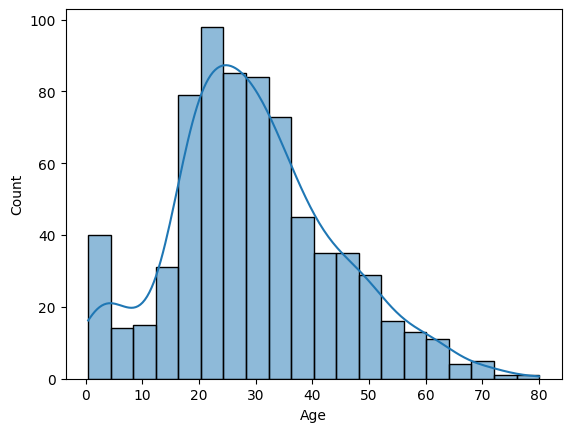

In [161]:
sns.histplot(x=titanic['Age'],kde=True)

<Axes: xlabel='Age'>

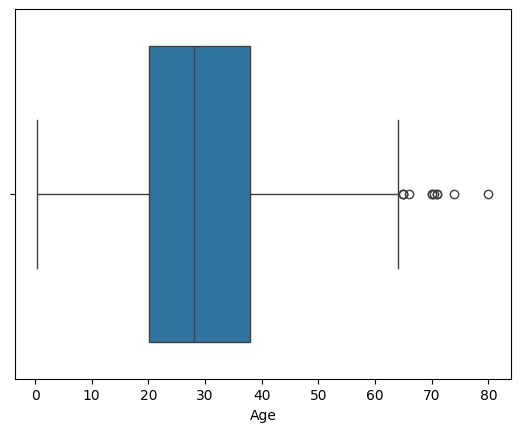

In [162]:
sns.boxplot(x=titanic['Age'])

In [163]:
titanic[titanic['Age'] > 65]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
33,34,0,2,"Wheadon, Mr. Edward H",male,66.0,0,0,C.A. 24579,10.5000,NaN,S
96,97,0,1,"Goldschmidt, Mr. George B",male,71.0,0,0,PC 17754,34.6542,A5,C
116,117,0,3,"Connors, Mr. Patrick",male,70.5,0,0,370369,7.7500,NaN,Q
493,494,0,1,"Artagaveytia, Mr. Ramon",male,71.0,0,0,PC 17609,49.5042,NaN,C
630,631,1,1,"Barkworth, Mr. Algernon Henry Wilson",male,80.0,0,0,27042,30.0000,A23,S
672,673,0,2,"Mitchell, Mr. Henry Michael",male,70.0,0,0,C.A. 24580,10.5000,NaN,S
745,746,0,1,"Crosby, Capt. Edward Gifford",male,70.0,1,1,WE/P 5735,71.0000,B22,S
851,852,0,3,"Svensson, Mr. Johan",male,74.0,0,0,347060,7.7750,NaN,S


In [164]:
titanic['Age'].skew()

np.float64(0.38910778230082704)

In [165]:
titanic['Age'].isnull().sum()/len(titanic['Age'])

np.float64(0.19865319865319866)

#  **Fare**
## **Conclusion**
- There are outliers(~80-512) ,max outlier value(512.329200)
- Column Contains Group Fare not an Individual Fare,We need to create a new column for individual
- Most People travel at low prices
- Data is highly postively skew(~4.78)
- There is no missing values.

In [166]:
# discriptive 
titanic['Fare'].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

<Axes: xlabel='Fare', ylabel='Count'>

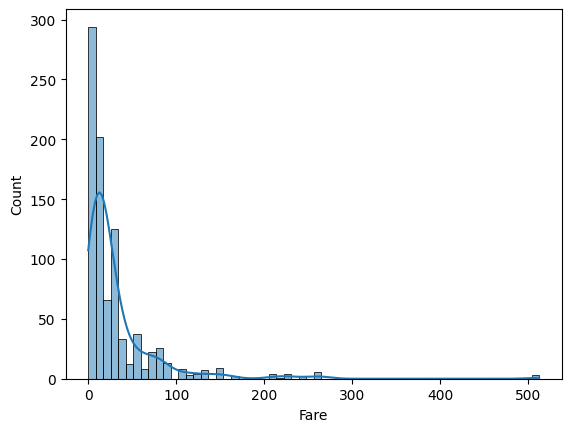

In [167]:
sns.histplot(x= titanic['Fare'],kde=True)

In [168]:
titanic['Fare'].skew()

np.float64(4.787316519674893)

<Axes: xlabel='Fare'>

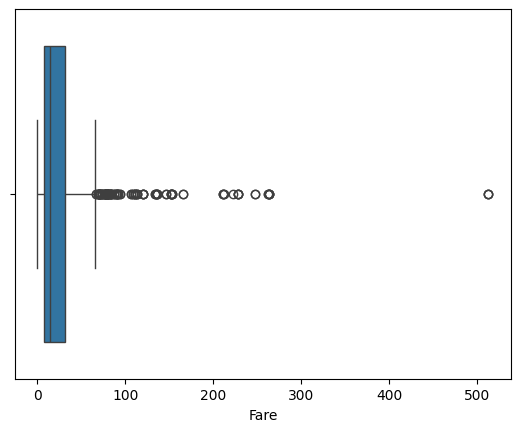

In [169]:
# Outlier detction
sns.boxplot(x= titanic['Fare'])

In [170]:
titanic[titanic['Fare'] >250]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
27,28,0,1,"Fortune, Mr. Charles Alexander",male,19.0,3,2,19950,263.0000,C23 C25 C27,S
88,89,1,1,"Fortune, Miss. Mabel Helen",female,23.0,3,2,19950,263.0000,C23 C25 C27,S
258,259,1,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,NaN,C
311,312,1,1,"Ryerson, Miss. Emily Borie",female,18.0,2,2,PC 17608,262.3750,B57 B59 B63 B66,C
341,342,1,1,"Fortune, Miss. Alice Elizabeth",female,24.0,3,2,19950,263.0000,C23 C25 C27,S
438,439,0,1,"Fortune, Mr. Mark",male,64.0,1,4,19950,263.0000,C23 C25 C27,S
679,680,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,PC 17755,512.3292,B51 B53 B55,C
737,738,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,PC 17755,512.3292,B101,C
742,743,1,1,"Ryerson, Miss. Susan Parker ""Suzette""",female,21.0,2,2,PC 17608,262.3750,B57 B59 B63 B66,C


In [171]:
titanic['Fare'].isnull().sum()

np.int64(0)

# **Categorical Columns**

In [172]:
titanic.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C


### **Sex**
### Conclusion:


In [173]:
titanic['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

## **Surived Column**
### **Conclusion**
- death people rate(~61.6%) is higher than survived,only (~38.4) people survived
- There is no missing Values.

In [174]:
titanic['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

<Axes: >

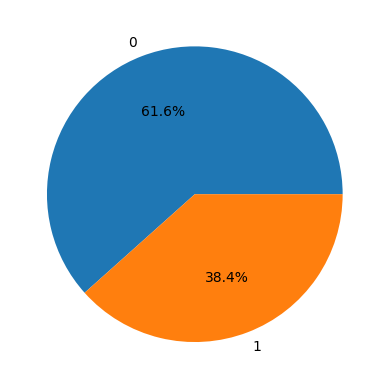

In [175]:
titanic['Survived'].value_counts().plot(kind='pie',autopct='%1.1f%%')

In [176]:
titanic['Survived'].isnull().sum()

np.int64(0)

## **PClass**
### **Conclusion**
- 3 class travellar highest , surpringly 1 class traveller are second  than 2 class (3>1>2)

In [177]:
titanic['Pclass'].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

<Axes: >

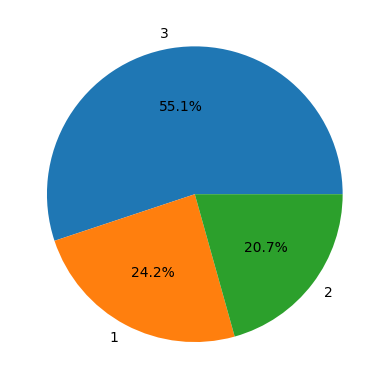

In [178]:
titanic['Pclass'].value_counts().plot(kind='pie',autopct = '%1.1f%%')

## **SibSp & Parch**
### **Conclusion**
- In Both features number of solo travellers are highest, than group of 1 
- in `sibsp` maximum group travellers are of 5
-  In `Parach` maximum group is of 6 
- These both columns overall represents the group travellers,we need to merge them (a new column with named `Family size`)
- We can also make new column for solo traveller(helps us to examine survival)

In [179]:
titanic['SibSp'].value_counts()

SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64

<Axes: xlabel='SibSp'>

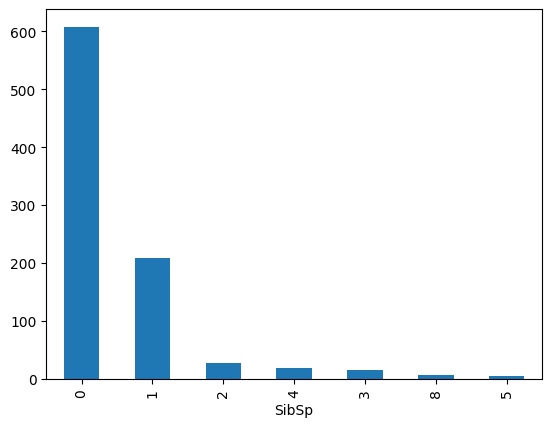

In [180]:
titanic['SibSp'].value_counts().plot(kind='bar')

In [181]:
titanic['Parch'].value_counts()

Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64

<Axes: xlabel='Parch'>

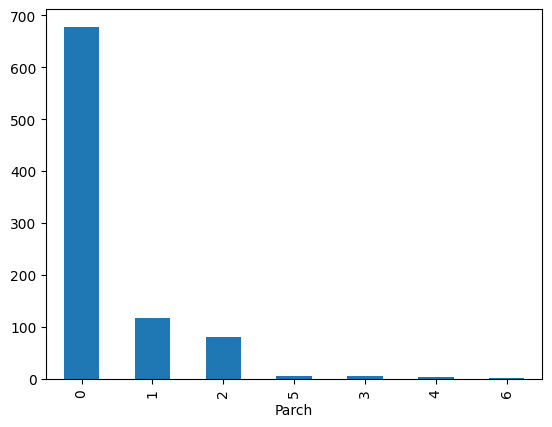

In [182]:
titanic['Parch'].value_counts().plot(kind='bar')

## **Embarked**
### **Conclusion**

In [183]:
titanic['Embarked'].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

<Axes: xlabel='Embarked'>

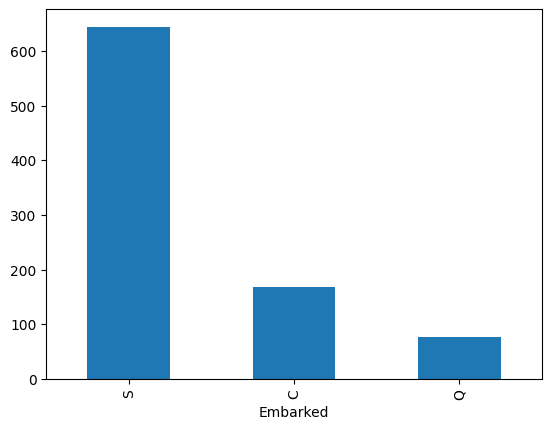

In [184]:
titanic['Embarked'].value_counts().plot(kind='bar')

## **Mixed Columns**
### **Need To Feature Enginerring To Mixed Columns**

## **Bivariate Analysis**

In [185]:
titanic.head(1)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.25,NaN,S


# Categorical - Categorical

## **Survived & Pclass**
### **Conclusion**
1) Pclass 1:
- 62.96% people were survived and 37.03% were not survived
- Survive rate is higher than death rate
2) Pclass 2:
- 47.28% people were survived where 52.71% people were not suvived
- Death rate is quite larger than survive rate.
3) Pclass 3:
-  Only 24.23% people were survived and remaining 75.76 were not survived
- death rate is too much higher than survived rate<br>
**Overall Conclusion**
- Pclass crates high impact on survival rate
- survival rate : Pcalss 1>2>3


In [186]:
pd.crosstab(titanic['Survived'],titanic['Pclass'],normalize= 'columns')*100

Pclass,1,2,3
Survived,,,
0,37.037037,52.717391,75.763747
1,62.962963,47.282609,24.236253


<Axes: xlabel='Pclass', ylabel='Survived'>

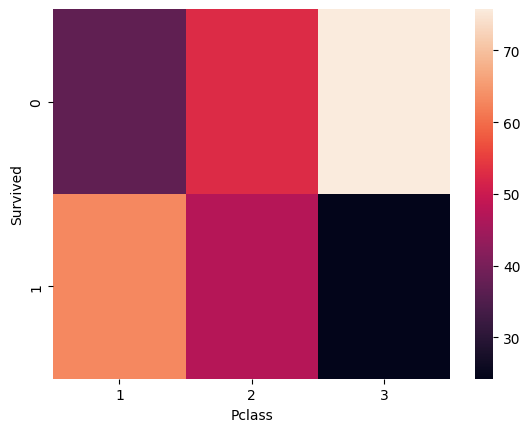

In [187]:
sns.heatmap(pd.crosstab(titanic['Survived'],titanic['Pclass'],normalize= 'columns')*100)

## **Survived & Sex**
### **Conclusion**
1) Female
- ~75% female were survived where remaining ~25% were not survived.
- Survival rate is 3 times higher than death rate 
2) Male
- only 18% male were survived and remaining 81% were not survived
- Death rate is too much high as compared to survived rate
**Overall Conclusion**
- Women survival rate is higher than man

In [188]:
pd.crosstab(titanic['Survived'],titanic['Sex'],normalize='columns')*100

Sex,female,male
Survived,,
0,25.796178,81.109185
1,74.203822,18.890815


<Axes: xlabel='Sex', ylabel='Survived'>

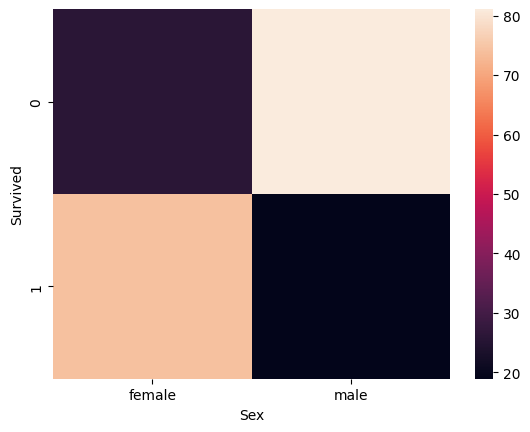

In [189]:
sns.heatmap(pd.crosstab(titanic['Survived'],titanic['Sex'],normalize='columns')*100)

## **Survived & Embarked**
### **Conclusion**
asumptions:
- Basically survival rate should not depend on Embarked but on comparing we see
c station travellars survival rate is higher than station Q and S 
1) It may be due to womens quantity is higher than man in that particular station 
- This assumption is not true on analysis we see (43% are womens )
2) or may be more travellers are of Pclass 1 
- This result goes write (60% is of Pclass 1 and 10% ,30% is of Pclass 2,3 respectively)

In [190]:
pd.crosstab(titanic['Survived'],titanic['Embarked'],normalize='columns')*100

Embarked,C,Q,S
Survived,,,
0,44.642857,61.038961,66.304348
1,55.357143,38.961039,33.695652


In [191]:
pd.crosstab(titanic['Sex'],titanic['Embarked'],normalize='columns')*100 ##assumptions 1

Embarked,C,Q,S
Sex,,,
female,43.452381,46.753247,31.521739
male,56.547619,53.246753,68.478261


In [192]:
pd.crosstab(titanic['Pclass'],titanic['Embarked'],normalize='columns')*100 ## assumptions 2

Embarked,C,Q,S
Pclass,,,
1,50.595238,2.597403,19.720497
2,10.119048,3.896104,25.465839
3,39.285714,93.506494,54.813665


## **Numerical - Categorical**

## **Survived & Age**

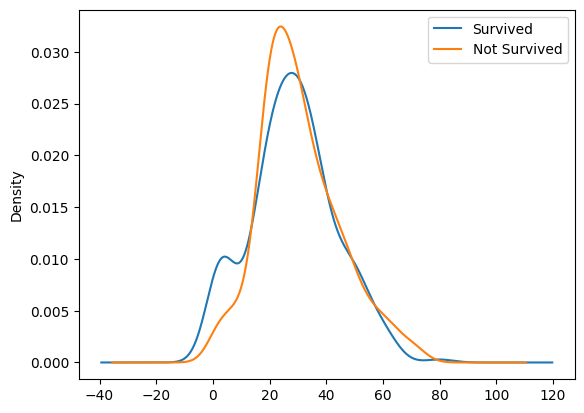

In [193]:
titanic[titanic['Survived']==1]['Age'].plot(kind='kde',label = 'Survived')
titanic[titanic['Survived']==0]['Age'].plot(kind='kde',label = 'Not Survived')
plt.legend()
plt.show()

## **Conclusion**
- age(1-10) survive rate is dominating over death rate 
- age(10-40) death rate is higher than survive rate

In [194]:
titanic[titanic['Pclass'] ==1]['Age'].mean()

np.float64(38.233440860215055)

## **Feature Enginnering**

In [195]:
# Fare column is of group not individual 
titanic['SibSp'].value_counts()

SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64

In [196]:
titanic[titanic['SibSp']==8]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
159,160,0,3,"Sage, Master. Thomas Henry",male,NaN,8,2,CA. 2343,69.55,NaN,S
180,181,0,3,"Sage, Miss. Constance Gladys",female,NaN,8,2,CA. 2343,69.55,NaN,S
201,202,0,3,"Sage, Mr. Frederick",male,NaN,8,2,CA. 2343,69.55,NaN,S
324,325,0,3,"Sage, Mr. George John Jr",male,NaN,8,2,CA. 2343,69.55,NaN,S
792,793,0,3,"Sage, Miss. Stella Anna",female,NaN,8,2,CA. 2343,69.55,NaN,S
846,847,0,3,"Sage, Mr. Douglas Bullen",male,NaN,8,2,CA. 2343,69.55,NaN,S
863,864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,CA. 2343,69.55,NaN,S


In [197]:
titanic[titanic['Ticket']=='CA. 2343']

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
159,160,0,3,"Sage, Master. Thomas Henry",male,NaN,8,2,CA. 2343,69.55,NaN,S
180,181,0,3,"Sage, Miss. Constance Gladys",female,NaN,8,2,CA. 2343,69.55,NaN,S
201,202,0,3,"Sage, Mr. Frederick",male,NaN,8,2,CA. 2343,69.55,NaN,S
324,325,0,3,"Sage, Mr. George John Jr",male,NaN,8,2,CA. 2343,69.55,NaN,S
792,793,0,3,"Sage, Miss. Stella Anna",female,NaN,8,2,CA. 2343,69.55,NaN,S
846,847,0,3,"Sage, Mr. Douglas Bullen",male,NaN,8,2,CA. 2343,69.55,NaN,S
863,864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,CA. 2343,69.55,NaN,S


In [198]:
titanic[titanic['Name'].str.contains('Sage',case=False)]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
159,160,0,3,"Sage, Master. Thomas Henry",male,NaN,8,2,CA. 2343,69.55,NaN,S
180,181,0,3,"Sage, Miss. Constance Gladys",female,NaN,8,2,CA. 2343,69.55,NaN,S
201,202,0,3,"Sage, Mr. Frederick",male,NaN,8,2,CA. 2343,69.55,NaN,S
324,325,0,3,"Sage, Mr. George John Jr",male,NaN,8,2,CA. 2343,69.55,NaN,S
641,642,1,1,"Sagesser, Mlle. Emma",female,24.0,0,0,PC 17477,69.30,B35,C
792,793,0,3,"Sage, Miss. Stella Anna",female,NaN,8,2,CA. 2343,69.55,NaN,S
846,847,0,3,"Sage, Mr. Douglas Bullen",male,NaN,8,2,CA. 2343,69.55,NaN,S
863,864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,CA. 2343,69.55,NaN,S


In [199]:
titanic1 = pd.read_csv(r"C:\Users\LENOVO\Downloads\test.csv")

In [200]:
df = pd.concat([titanic,titanic1])

In [201]:
df[df['Ticket']=='CA. 2343']

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
159,160,0.0,3,"Sage, Master. Thomas Henry",male,NaN,8,2,CA. 2343,69.55,NaN,S
180,181,0.0,3,"Sage, Miss. Constance Gladys",female,NaN,8,2,CA. 2343,69.55,NaN,S
201,202,0.0,3,"Sage, Mr. Frederick",male,NaN,8,2,CA. 2343,69.55,NaN,S
324,325,0.0,3,"Sage, Mr. George John Jr",male,NaN,8,2,CA. 2343,69.55,NaN,S
792,793,0.0,3,"Sage, Miss. Stella Anna",female,NaN,8,2,CA. 2343,69.55,NaN,S
846,847,0.0,3,"Sage, Mr. Douglas Bullen",male,NaN,8,2,CA. 2343,69.55,NaN,S
863,864,0.0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,CA. 2343,69.55,NaN,S
188,1080,NaN,3,"Sage, Miss. Ada",female,NaN,8,2,CA. 2343,69.55,NaN,S
342,1234,NaN,3,"Sage, Mr. John George",male,NaN,1,9,CA. 2343,69.55,NaN,S
360,1252,NaN,3,"Sage, Master. William Henry",male,14.5,8,2,CA. 2343,69.55,NaN,S


In [202]:
df['Individual_fare'] = df['Fare']/(df['SibSp']+df['Parch'] + 1)

In [203]:
df[['Individual_fare','Fare']].describe()

,Individual_fare,Fare
count,1308.000000,1308.000000
mean,20.518215,33.295479
std,35.774337,51.758668
min,0.000000,0.000000
25%,7.452767,7.895800
50%,8.512483,14.454200
75%,24.237500,31.275000
max,512.329200,512.329200


In [204]:
df['Family_Size'] = df['SibSp'] + df['Parch'] + 1

In [205]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Individual_fare,Family_Size
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,3.62500,2
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,35.64165,2
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,7.92500,1
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,26.55000,2
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,8.05000,1


In [206]:
# Family type
# 1--> Alone
#2-4 --> small 
#5< ---> Large
def family_size(num):
    if(num==1):
        return "Alone"
    elif(num<5):
        return 'Small'
    else:
        return 'Large'

In [207]:
df['Family_Type'] = df['Family_Size'].apply(family_size)

In [208]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Individual_fare,Family_Size,Family_Type
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,3.62500,2,Small
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,35.64165,2,Small
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,7.92500,1,Alone
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,26.55000,2,Small
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,8.05000,1,Alone


In [209]:
df['Family_Type'].value_counts()

Family_Type
Alone    790
Small    437
Large     82
Name: count, dtype: int64

In [210]:
df['Family_Type'] = df['Family_Type'].astype('category')

In [211]:
df = df.reset_index(drop=True)

In [212]:
pd.crosstab(df['Survived'],df['Family_Type'],normalize='columns')*100

Family_Type,Alone,Large,Small
Survived,,,
0.0,69.646182,83.870968,42.123288
1.0,30.353818,16.129032,57.876712


## Family_Type  &  Survived
### **Conclusion**
1)  `Alone`:
- The Death rate is higher (~69.64%) than survival rate (~30.35%)
- assumptions :
1) More quantity of man than women 
- validity (True) Female(~24.55%) and Male(~75.44%)
2) travellers are of lower Pclass(may be 2 or 3)
- validity(True) plcass 3(~59.74) only ~20% of Pclass 2 or 1 

2) `Large`:
- Death rate too much high (~83.87)%  and survival rate is only(~16.12%)
- Resons:
1) ~84.14%  travel in 3 Pclass(less survival rate)
- male and female ratio is same(50%)

3) `small`:
- Here survival rate(~57.87) is higher than death rate(~42.12%)
- reasons:
1) feamales is in higher percentage(~52.86) 
- here Pclass 1,2,3is approx equally distributed(34%,26%,38) respectively


In [213]:
pd.crosstab(df['Sex'],df['Family_Type'],normalize='columns')*100

Family_Type,Alone,Large,Small
Sex,,,
female,24.556962,50.0,52.860412
male,75.443038,50.0,47.139588


In [214]:
pd.crosstab(df['Pclass'],df['Family_Type'],normalize='columns')*100

Family_Type,Alone,Large,Small
Pclass,,,
1,20.253165,13.414634,34.782609
2,20.000000,2.439024,26.773455
3,59.746835,84.146341,38.443936


In [215]:
# create a new column with surname 
df['surname'] = df['Name'].str.split(',').str.get(0)

In [216]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Individual_fare,Family_Size,Family_Type,surname
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,3.62500,2,Small,Braund
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,35.64165,2,Small,Cumings
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,7.92500,1,Alone,Heikkinen
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,26.55000,2,Small,Futrelle
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,8.05000,1,Alone,Allen
